In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/diabetes_patients_10000_full.csv')
df

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic
...,...,...,...,...,...,...,...,...,...,...
9995,9996,52.0,Female,248.0,1.03,33.1,38.0,271.0,5.3,Diabetic
9996,9997,71.0,Male,111.0,0.92,31.3,40.0,158.0,6.7,Diabetic
9997,9998,49.0,Female,230.0,0.67,26.0,48.0,180.0,10.5,Diabetic
9998,9999,22.0,Male,184.0,0.91,26.1,19.0,195.0,6.1,Diabetic


In [3]:
df.drop(['Patient_ID'] , axis = 1 , inplace = True)

In [4]:
df.reset_index( drop = True, inplace = True)

In [5]:
df.duplicated().sum()

0

In [6]:
df.isnull().sum().sort_values(ascending = False).head(20)

Creatinine           56
Blood_Sugar_Level    53
BMI                  51
Urea                 51
Gender               40
Cholesterol          32
Age                  14
HbA1c                 0
Class                 0
dtype: int64

In [7]:
df.shape

(10000, 9)

In [8]:
df.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                9986 non-null   float64
 1   Gender             9960 non-null   object 
 2   Blood_Sugar_Level  9947 non-null   float64
 3   Creatinine         9944 non-null   float64
 4   BMI                9949 non-null   float64
 5   Urea               9949 non-null   float64
 6   Cholesterol        9968 non-null   float64
 7   HbA1c              10000 non-null  float64
 8   Class              10000 non-null  object 
dtypes: float64(7), object(2)
memory usage: 703.2+ KB


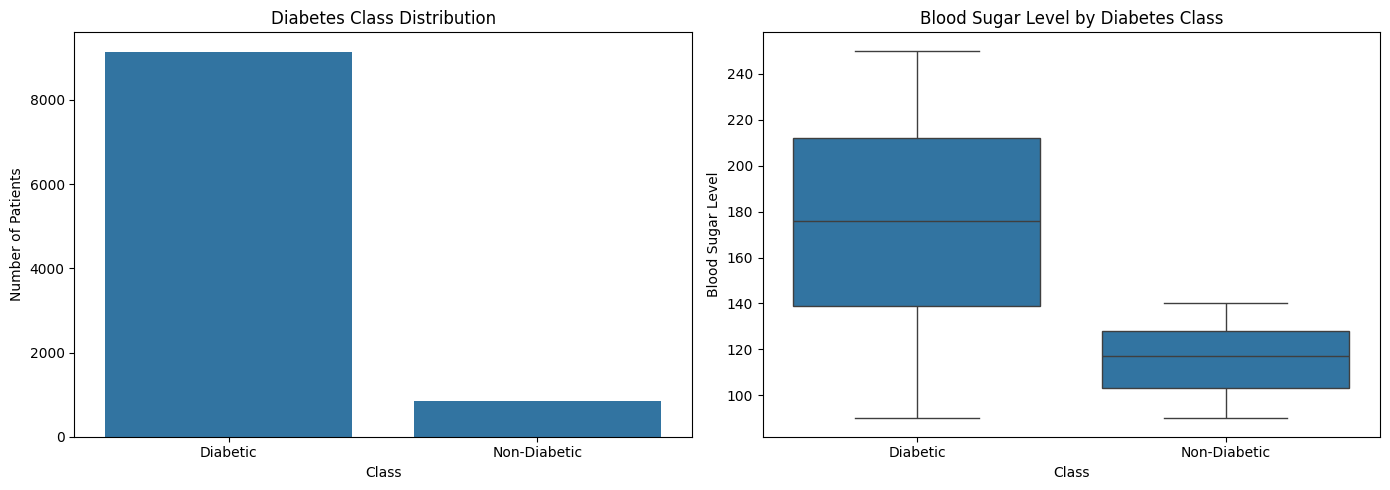

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    x='Class',
    order=df['Class'].value_counts().index,
    ax=axes[0]
)
axes[0].set_title('Diabetes Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Patients')

sns.boxplot(
    data=df,
    x='Class',
    y='Blood_Sugar_Level',
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Blood Sugar Level by Diabetes Class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Blood Sugar Level')

plt.tight_layout()
plt.show()

In [11]:
df.dropna(axis = 0 , inplace = True)

In [12]:
df.shape

(9932, 9)

In [13]:
df.select_dtypes(include=['object']).columns

Index(['Gender', 'Class'], dtype='object')

In [14]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
ohe_encoded = ohe.fit_transform(df[['Gender']]).toarray()

In [15]:
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(['Gender']),
    index=df.index
)

df = pd.concat([df, ohe_df], axis=1)

In [16]:
df

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class,Gender_Female,Gender_Male
0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic,0.0,1.0
1,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic,0.0,1.0
2,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic,0.0,1.0
3,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic,1.0,0.0
4,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,52.0,Female,248.0,1.03,33.1,38.0,271.0,5.3,Diabetic,1.0,0.0
9996,71.0,Male,111.0,0.92,31.3,40.0,158.0,6.7,Diabetic,0.0,1.0
9997,49.0,Female,230.0,0.67,26.0,48.0,180.0,10.5,Diabetic,1.0,0.0
9998,22.0,Male,184.0,0.91,26.1,19.0,195.0,6.1,Diabetic,0.0,1.0


In [17]:
df.drop(['Gender'] , axis=1 , inplace = True)

In [18]:
df.reset_index(drop = True , inplace =True)

In [19]:
from sklearn.preprocessing import StandardScaler , MinMaxScaler


In [20]:
X = df.drop(['Class'], axis = 1)
y = df['Class']

In [21]:
df.reset_index(drop=True, inplace=True)

In [22]:
X.head()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Gender_Female,Gender_Male
0,60.0,96.0,1.34,22.5,23.0,176.0,8.6,0.0,1.0
1,77.0,241.0,1.02,19.0,28.0,209.0,7.5,0.0,1.0
2,21.0,229.0,1.02,25.9,32.0,151.0,9.1,0.0,1.0
3,30.0,177.0,0.88,22.1,36.0,176.0,5.1,1.0,0.0
4,26.0,178.0,1.20,31.8,44.0,287.0,5.2,1.0,0.0


In [23]:
y.head()

0    Diabetic
1    Diabetic
2    Diabetic
3    Diabetic
4    Diabetic
Name: Class, dtype: object

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (7945, 9)  y_train =  (7945,)
X_test  =  (1987, 9)  y_test  =  (1987,)


In [25]:
X_train.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Gender_Female,Gender_Male
count,7945.000000,7945.000000,7945.000000,7945.000000,7945.000000,7945.000000,7945.000000,7945.000000,7945.000000
mean,50.073379,168.889616,1.101173,26.750875,35.020516,225.492637,7.498364,0.505349,0.494651
std,17.670035,46.101267,0.286766,4.770135,11.836200,43.751216,1.752249,0.500003,0.500003
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000,0.000000,0.000000
25%,35.000000,129.000000,0.850000,22.600000,25.000000,188.000000,6.000000,0.000000,0.000000
50%,50.000000,168.000000,1.100000,26.700000,35.000000,226.000000,7.500000,1.000000,0.000000
75%,65.000000,208.000000,1.350000,30.900000,45.000000,263.000000,9.000000,1.000000,1.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000,1.000000,1.000000


In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
model = LogisticRegression(
    
    C = 1.0,
    # solver='lbfgs',
    max_iter=1000,
    fit_intercept=True,
)

In [28]:
model.fit(X_train , y_train)

LogisticRegression(max_iter=1000)

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report ,confusion_matrix ,roc_curve,auc

In [30]:
y_pred = model.predict(X_test)

In [31]:
score = accuracy_score(y_test , y_pred)
print(score)

0.9703069954705587


In [32]:
pre = precision_score(y_test, y_pred, average='macro')
print(pre)

0.9299786588790295


In [33]:
recall = recall_score(y_test, y_pred, average='macro')
print(recall)

0.871792547508822


In [34]:
clas = classification_report(y_test , y_pred)
print(clas)

              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      1817
Non-Diabetic       0.88      0.75      0.81       170

    accuracy                           0.97      1987
   macro avg       0.93      0.87      0.90      1987
weighted avg       0.97      0.97      0.97      1987



In [35]:
df.columns

Index(['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol',
       'HbA1c', 'Class', 'Gender_Female', 'Gender_Male'],
      dtype='object')

In [36]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [37]:
print(accuracy_score(y_test , y_pred))

0.9094111726220433


In [38]:
from sklearn.naive_bayes import GaussianNB

In [39]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_test)

print('GaussianNB accuracy:', accuracy_score(y_test, y_pred_gnb))
print(classification_report(y_test, y_pred_gnb))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred_gnb))

GaussianNB accuracy: 0.98842476094615
              precision    recall  f1-score   support

    Diabetic       0.99      1.00      0.99      1817
Non-Diabetic       1.00      0.86      0.93       170

    accuracy                           0.99      1987
   macro avg       0.99      0.93      0.96      1987
weighted avg       0.99      0.99      0.99      1987

Confusion matrix:
[[1817    0]
 [  23  147]]


In [40]:
model = SVC(C=0.1, kernel='linear',gamma='auto')

model.fit(X_train, y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [41]:
y_pred = model.predict(X_test)

In [42]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


0.9703069954705587
              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      1817
Non-Diabetic       0.89      0.74      0.81       170

    accuracy                           0.97      1987
   macro avg       0.93      0.87      0.90      1987
weighted avg       0.97      0.97      0.97      1987



In [43]:
#!pip install graphviz pydot 
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [44]:
model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=100
    )

In [45]:
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred_test, labels=model.classes_))

Train accuracy: 1.0
Test accuracy: 1.0
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1817
Non-Diabetic       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

Confusion matrix:
[[1817    0]
 [   0  170]]


In [46]:
grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

In [47]:
grid = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, None],
                         'min_samples_leaf': [1, 5, 10],
                         'min_samples_split': [2, 10, 20]},
             scoring='accuracy')

In [48]:
best_model = grid.best_estimator_


In [49]:
y_pred = best_model.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

1.0
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1817
Non-Diabetic       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987



In [50]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier


# Create the RFE model 
model = RandomForestClassifier(random_state=42)
rfe = RFE(estimator=model, n_features_to_select=None)  # None , float , int
X_train_rf=rfe.fit_transform(X_train,y_train)
X_test_rf=rfe.transform(X_test)



In [51]:

rfe.ranking_

array([3, 1, 2, 1, 4, 1, 1, 5, 6])

In [52]:

rfe.support_

array([False,  True, False,  True, False,  True,  True, False, False])

In [53]:
X_train.columns[rfe.get_support()]

Index(['Blood_Sugar_Level', 'BMI', 'Cholesterol', 'HbA1c'], dtype='object')

In [54]:
X_train.iloc[:,rfe.support_].head()

,Blood_Sugar_Level,BMI,Cholesterol,HbA1c
8734,231.0,27.6,291.0,8.6
6896,180.0,26.1,197.0,9.9
9661,207.0,30.3,170.0,10.3
5438,103.0,23.2,282.0,5.3
4082,112.0,28.3,202.0,9.3


In [55]:
grid = GridSearchCV(estimator= RandomForestClassifier(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, None],
                         'min_samples_leaf': [1, 5, 10],
                         'min_samples_split': [2, 10, 20]},
             scoring='accuracy')

In [56]:
best_model_RFC = grid.best_estimator_


In [57]:
y_pred = best_model_RFC.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

1.0
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1817
Non-Diabetic       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987



## Additional visualizations (diabetes patients)

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')
dp = pd.read_csv(r'/Users/pawn/Desktop/NTI/diabetes_patients_10000_full.csv')
dp.shape

(10000, 10)

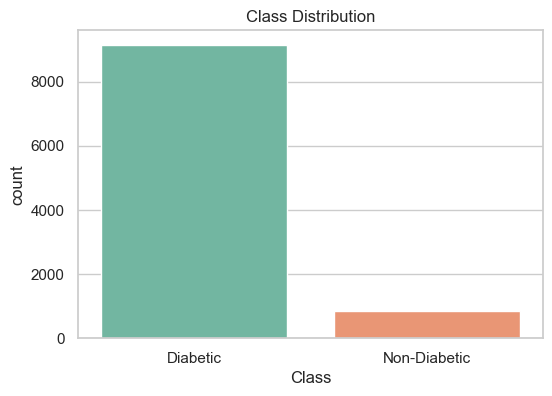

In [59]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=dp, palette='Set2', hue='Class', legend=False)
plt.title('Class Distribution')
plt.show()

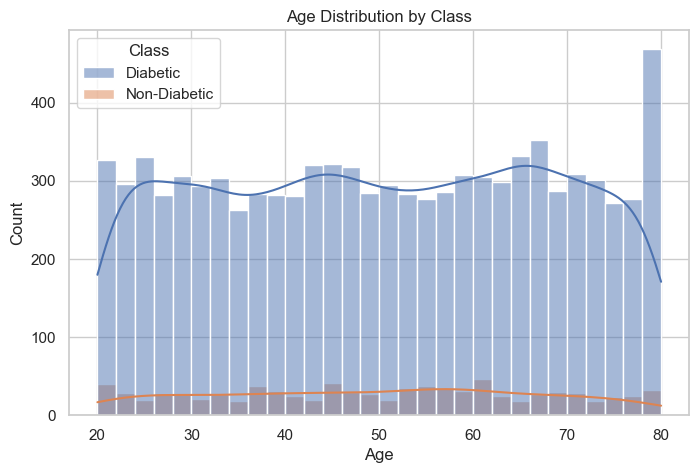

In [60]:
plt.figure(figsize=(8, 5))
sns.histplot(data=dp, x='Age', hue='Class', bins=30, kde=True)
plt.title('Age Distribution by Class')
plt.show()

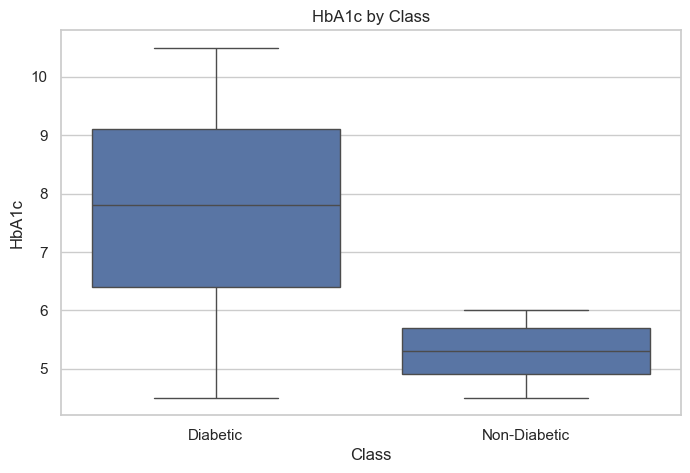

In [61]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='HbA1c', data=dp)
plt.title('HbA1c by Class')
plt.show()

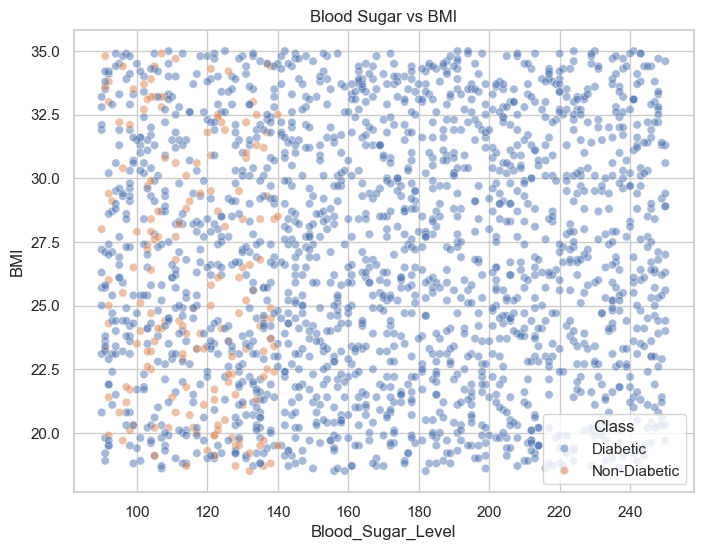

In [62]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Blood_Sugar_Level', y='BMI', hue='Class', data=dp.sample(2000, random_state=1), alpha=0.5)
plt.title('Blood Sugar vs BMI')
plt.show()

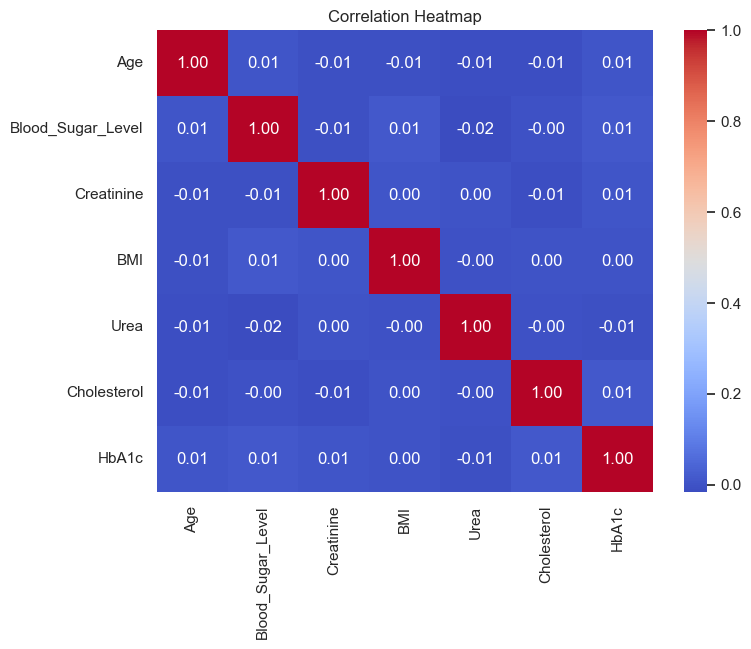

In [63]:
plt.figure(figsize=(8, 6))
sns.heatmap(dp.select_dtypes('number').drop(columns='Patient_ID').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()